# Preprocesado 

1. Carga las imágenes y las máscaras del dataset.
2. Crea un split desarrollo/test.
3. Aplica escala, reducción de ruido y gamma.
4. Construye 11 canales: Lab, YCrCb, RGB, HSV, ExG y forma (DoG).
5. Calibra el DoG solo con desarrollo.
6. Guarda `dataset_preprocesado_grid/` con 66 subcarpetas (una por
   configuración), cada una con un `.npy` por imagen, `nombres.txt`,
   `split.npz` y `config.json`.

Las rutas, la semilla, los parámetros de calibración y el grid de
configuraciones están en las celdas **Constantes** y **Configuración del pipeline**.

## Imports

In [1]:
import json
import os
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

from aux import CANALES

## Constantes

Rutas, reproducibilidad, calibración del DoG, parámetros de las figuras
y frecuencia de guardado. Todo lo que se ajusta está en estas celdas.


In [2]:
RUTA_IMGS = './dataset_manzanas/imagenes'
RUTA_MASCARAS = './dataset_manzanas/mascaras'
RUTA_SALIDA_GRID = './dataset_preprocesado_grid'

# Test externo: solo se usa al final, nunca para calibrar ni elegir parámetros
RUTA_TEST_IMGS = './manzanas_test_set/imagenes'
RUTA_TEST_MASCARAS = './manzanas_test_set/mascaras'
RUTA_SALIDA_TEST = './dataset_preprocesado_test'

EXT_IMAGEN = '.png'

SEMILLA = 42

NUM_HILOS = 4
DPI_FIGURAS = 110
BINS_HIST = 40
FIG_TAM_HIST = (7, 3.5)
FIG_TAM_CANALES = (16, 6)
FIG_TAM_MUESTRAS = (15, 4)

# Calibración del DoG
DOG_RATIO = 1.6
AREA_MIN = 50
AREA_MAX = 5000
ASPECTO_MIN = 0.3
PERCENTILES_RADIO = (10, 50, 90)
PERCENTIL_DOG = 99.0
PASO_DOG = 25

# Guardado del grid
CADA_N_IMAGENES = 10

cv.setNumThreads(NUM_HILOS)
plt.rcParams['figure.dpi'] = DPI_FIGURAS


## 1. Configuración del pipeline

Define `Ruido`, `ConfigPreprocesado`, el grid (`CONFIGS`) y la configuración
activa (`CFG`).

```python
CFG = ConfigPreprocesado(
    escala=0.5,
    ruido=Ruido('bilateral', d=5, sigma=25),
    gamma=1.5,
)
```

In [3]:
class Ruido:
    """Reducción de ruido. Los valores de ``k`` deben ser impares."""

    def __init__(self, metodo='mediana', k=3, d=9, sigma=75.0):
        self.metodo = metodo
        self.k = k
        self.d = d
        self.sigma = sigma

    def id(self):
        if self.metodo == 'ninguno':
            return 'ninguno'
        if self.metodo == 'bilateral':
            return f'bilat_d{self.d}_s{self.sigma:g}'
        return f'{self.metodo}_k{self.k}'

    def como_dict(self):
        return {
            'metodo': self.metodo,
            'k': self.k,
            'd': self.d,
            'sigma': self.sigma,
        }

class ConfigPreprocesado:
    """Configuración completa del pipeline."""

    def __init__(self, escala=1.0, ruido=None, gamma=1.0,
                 dog_ratio=DOG_RATIO):
        self.escala = escala
        self.ruido = ruido if ruido is not None else Ruido()
        self.gamma = gamma
        self.dog_ratio = dog_ratio

    def id(self):
        return f'e{self.escala:g}_{self.ruido.id()}_g{self.gamma:g}'

    def como_dict(self):
        return {
            'id': self.id(),
            'escala': self.escala,
            'ruido': self.ruido.como_dict(),
            'gamma': self.gamma,
            'dog_ratio': self.dog_ratio,
        }


# Grid de configuraciones 
ESCALAS_GRID = (1.0, 0.5)
GAMMAS_GRID = (0.7, 1.0, 1.5)
RUIDOS_GRID = (
    Ruido('ninguno'),
    Ruido('gaussiano', k=3),
    Ruido('gaussiano', k=5),
    Ruido('gaussiano', k=7),
    Ruido('mediana', k=3),
    Ruido('mediana', k=5),
    Ruido('mediana', k=7),
    Ruido('bilateral', d=5, sigma=25),
    Ruido('bilateral', d=9, sigma=25),
    Ruido('bilateral', d=5, sigma=75),
    Ruido('bilateral', d=9, sigma=75),
)
CONFIGS = [
    ConfigPreprocesado(escala=escala, ruido=ruido, gamma=gamma)
    for escala in ESCALAS_GRID
    for ruido in RUIDOS_GRID
    for gamma in GAMMAS_GRID
]

CFG = ConfigPreprocesado()

## 2. Etapas de imagen 

Escala, ruido y gamma. La escala usa `INTER_AREA` para color; las máscaras se
reescalan con `INTER_NEAREST` al cargarlas en los modelos.


In [4]:
def redimensionar(img, escala, interpolacion=cv.INTER_AREA):
    if escala == 1.0:
        return img
    alto, ancho = img.shape[:2]
    nuevo = (max(1, int(round(ancho * escala))),
             max(1, int(round(alto * escala))))
    return cv.resize(img, nuevo, interpolation=interpolacion)

def _validar_impar(k):
    if k <= 0 or k % 2 == 0:
        raise ValueError(f'El tamaño de kernel debe ser impar y positivo, no {k}.')

def aplicar_ruido(img_rgb, ruido):
    metodo = ruido.metodo
    if metodo == 'ninguno':
        return img_rgb
    if metodo == 'gaussiano':
        _validar_impar(ruido.k)
        return cv.GaussianBlur(img_rgb, (ruido.k, ruido.k), 0)
    if metodo == 'mediana':
        _validar_impar(ruido.k)
        return cv.medianBlur(img_rgb, ruido.k)
    if metodo == 'bilateral':
        return cv.bilateralFilter(img_rgb, d=ruido.d,
                                  sigmaColor=ruido.sigma,
                                  sigmaSpace=ruido.sigma)
    raise ValueError(f'Método de ruido desconocido: {metodo}')

def aplicar_gamma(img_rgb, gamma):
    if gamma == 1.0:
        return img_rgb
    norm = img_rgb.astype(np.float32) / 255.0
    return np.clip(255.0 * norm ** gamma, 0, 255).astype(np.uint8)

def preparar_rgb(img_rgb, cfg):
    img = redimensionar(img_rgb, cfg.escala, cv.INTER_AREA)
    img = aplicar_ruido(img, cfg.ruido)
    return aplicar_gamma(img, cfg.gamma)

## 3. Canales de color 

`h` se reescala de 0-179 a 0-255 para que todos los canales pesen de forma
parecida en modelos basados en distancias. `exg` se recorta a 0-255.


In [5]:
def canales_color(img_rgb):
    lab = cv.cvtColor(img_rgb, cv.COLOR_RGB2Lab)
    ycc = cv.cvtColor(img_rgb, cv.COLOR_RGB2YCrCb)
    hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)
    r, g, b = cv.split(img_rgb)

    h = np.round(hsv[:, :, 0].astype(np.float32) * (255.0 / 180.0)).astype(np.uint8)
    exg = np.clip(2 * g.astype(np.int16) - r.astype(np.int16) - b.astype(np.int16),
                  0, 255).astype(np.uint8)

    return {
        'l': lab[:, :, 0],
        'a': lab[:, :, 1],
        'b': lab[:, :, 2],
        'y': ycc[:, :, 0],
        'cr': ycc[:, :, 1],
        'cb': ycc[:, :, 2],
        'r': r,
        'h': h,
        's': hsv[:, :, 1],
        'exg': exg,
    }

## 4. Filtro de forma y pila final

El DoG se calcula a varias escalas y se toma el máximo. Multiplicar por
`sigma**2` hace comparables las respuestas. La normalización usa el percentil
99 de las respuestas positivas en desarrollo.


In [6]:
def dog_multiescala(canal, sigmas, ratio=DOG_RATIO):
    if len(sigmas) == 0:
        raise ValueError('Se necesita al menos una sigma para el DoG.')
    canal = canal.astype(np.float32)
    respuestas = []
    for s in sigmas:
        s = float(s)
        fino = cv.GaussianBlur(canal, (0, 0), s)
        grueso = cv.GaussianBlur(canal, (0, 0), s * ratio)
        respuestas.append((fino - grueso) * (s * s))
    return np.max(np.stack(respuestas), axis=0)

def normalizar_dog(dog, ref):
    if ref <= 0:
        raise ValueError('La referencia del DoG debe ser positiva.')
    return np.clip(255.0 * np.clip(dog / ref, 0.0, 1.0), 0, 255).astype(np.uint8)

def preprocesar(img_rgb, cfg, sigmas, dog_ref):
    img = preparar_rgb(img_rgb, cfg)
    canales = canales_color(img)
    canales['blob'] = normalizar_dog(
        dog_multiescala(canales['b'], sigmas, cfg.dog_ratio), dog_ref)
    return np.dstack([canales[k] for k in CANALES]).astype(np.uint8)

## 5. Calibración del DoG con desarrollo

Para un disco de radio `r`, la respuesta DoG es máxima cuando
`sigma ≈ r / sqrt(2)`. Se estima el radio equivalente de cada manzana
(`sqrt(area/pi)`) y se usan los percentiles 10, 50 y 90.


In [7]:
def radios_manzanas(mascaras, indices, area_min=AREA_MIN,
                    area_max=AREA_MAX, aspecto_min=ASPECTO_MIN):
    radios = []
    for i in indices:
        m = np.where(mascaras[i] > 0, 1, 0).astype(np.uint8)
        n, _, stats, _ = cv.connectedComponentsWithStats(m, connectivity=8)
        for j in range(1, n):
            area = stats[j, cv.CC_STAT_AREA]
            ancho = stats[j, cv.CC_STAT_WIDTH]
            alto = stats[j, cv.CC_STAT_HEIGHT]
            aspecto = min(ancho, alto) / max(ancho, alto)
            if area_min <= area <= area_max and aspecto >= aspecto_min:
                radios.append(np.sqrt(area / np.pi))
    if not radios:
        raise ValueError('No hay manzanas válidas para calibrar el DoG.')
    return np.asarray(radios, dtype=np.float64)

def estimar_sigmas(radios, escala=1.0,
                   percentiles=PERCENTILES_RADIO):
    sigmas = np.percentile(radios * escala, percentiles) / np.sqrt(2)
    return tuple(np.round(sigmas, 1).tolist())

def referencia_dog(imagenes, idx_train, cfg, sigmas,
                   percentil=PERCENTIL_DOG, paso=PASO_DOG):
    valores = []
    for i in idx_train:
        img = preparar_rgb(imagenes[i], cfg)
        b = cv.cvtColor(img, cv.COLOR_RGB2Lab)[:, :, 2]
        d = dog_multiescala(b, sigmas, cfg.dog_ratio)
        valores.append(d[d > 0][::paso])
    valores = np.concatenate(valores)
    if len(valores) == 0:
        raise ValueError('El DoG no produjo respuestas positivas en desarrollo.')
    return float(np.percentile(valores, percentil))

def calibrar(imagenes, mascaras, idx_train, cfg):
    radios = radios_manzanas(mascaras, idx_train)
    sigmas = estimar_sigmas(radios, cfg.escala)
    dog_ref = referencia_dog(imagenes, idx_train, cfg, sigmas)
    return radios, sigmas, dog_ref

## 6. Carga de imágenes y split

Se crea un split para que los resultados sean comparables.


In [8]:
nombres = sorted(
    os.path.splitext(f)[0] for f in os.listdir(RUTA_IMGS)
    if f.lower().endswith(EXT_IMAGEN))

imagenes = []
mascaras = []
for nombre in nombres:
    img = cv.imread(os.path.join(RUTA_IMGS, nombre + EXT_IMAGEN),
                    cv.IMREAD_COLOR_RGB)
    mask = cv.imread(os.path.join(RUTA_MASCARAS, nombre + EXT_IMAGEN),
                     cv.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        raise FileNotFoundError(nombre)
    imagenes.append(img)
    mascaras.append(np.where(mask > 0, 255, 0).astype(np.uint8))

# Todo el dataset original es desarrollo, el k-fold se hace sobre estas imágenes
idx_train = np.arange(len(nombres))
idx_test = np.array([], dtype=int)

alto, ancho = imagenes[0].shape[:2]
print(f'{len(nombres)} imágenes de {ancho}x{alto}')
print(f'desarrollo: {len(idx_train)} | test interno: {len(idx_test)}')
print(f'píxeles de manzana: {100 * np.mean([m.mean() / 255 for m in mascaras]):.2f} %')

100 imágenes de 720x1280
desarrollo: 100 | test interno: 0
píxeles de manzana: 4.26 %


In [9]:
nombres_test = sorted(
    os.path.splitext(f)[0] for f in os.listdir(RUTA_TEST_IMGS)
    if f.lower().endswith(EXT_IMAGEN))

imagenes_test = []
mascaras_test = []
for nombre in nombres_test:
    img = cv.imread(os.path.join(RUTA_TEST_IMGS, nombre + EXT_IMAGEN),
                    cv.IMREAD_COLOR_RGB)
    mask = cv.imread(os.path.join(RUTA_TEST_MASCARAS, nombre + EXT_IMAGEN),
                     cv.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        raise FileNotFoundError(nombre)
    imagenes_test.append(img)
    mascaras_test.append(np.where(mask > 0, 255, 0).astype(np.uint8))

idx_test_externo = np.arange(len(nombres_test))
alto, ancho = imagenes_test[0].shape[:2]
print(f'test externo: {len(nombres_test)} imágenes de {ancho}x{alto}')
print(f'píxeles de manzana (test): '
      f'{100 * np.mean([m.mean() / 255 for m in mascaras_test]):.2f} %')

test externo: 30 imágenes de 720x1280
píxeles de manzana (test): 2.69 %


5738 manzanas analizadas (desarrollo)
radio equivalente: p10=7.8, mediana=12.4, p90=20.3 px
escalas DoG: sigma = radio/sqrt(2) -> (5.5, 8.8, 14.4)
DOG_REF (p99 de respuestas positivas en dev) = 1745.1


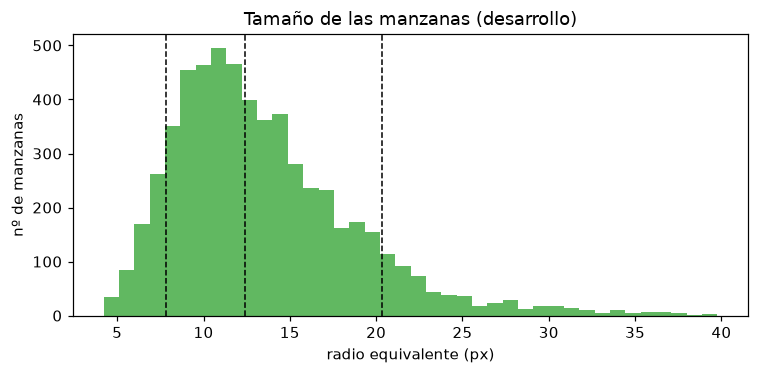

In [10]:
radios, SIGMAS, DOG_REF = calibrar(imagenes, mascaras, idx_train, CFG)
p10, p50, p90 = np.percentile(radios, PERCENTILES_RADIO)
print(f'{len(radios)} manzanas analizadas (desarrollo)')
print(f'radio equivalente: p10={p10:.1f}, mediana={p50:.1f}, p90={p90:.1f} px')
print(f'escalas DoG: sigma = radio/sqrt(2) -> {SIGMAS}')
print(f'DOG_REF (p99 de respuestas positivas en dev) = {DOG_REF:.1f}')

fig, ax = plt.subplots(figsize=FIG_TAM_HIST)
ax.hist(radios, bins=BINS_HIST, color='tab:green', alpha=0.75)
for r in (p10, p50, p90):
    ax.axvline(r, color='k', ls='--', lw=1)
ax.set_xlabel('radio equivalente (px)')
ax.set_ylabel('nº de manzanas')
ax.set_title('Tamaño de las manzanas (desarrollo)')
plt.tight_layout()
plt.show()

## 7. Comprobación visual


forma (1280, 720, 11)
 0 l     min=  1 max=253 media= 113.7
 1 a     min= 94 max=170 media= 116.0
 2 b     min=105 max=222 media= 151.8
 3 y     min=  2 max=250 media= 104.2
 4 cr    min=103 max=189 media= 125.8
 5 cb    min=  4 max=151 media= 106.3
 6 r     min=  0 max=255 media= 101.2
 7 h     min=  0 max=252 media=  66.1
 8 s     min=  0 max=255 media= 150.6
 9 exg   min=  0 max=255 media=  60.1
10 blob  min=  0 max=255 media=  30.3


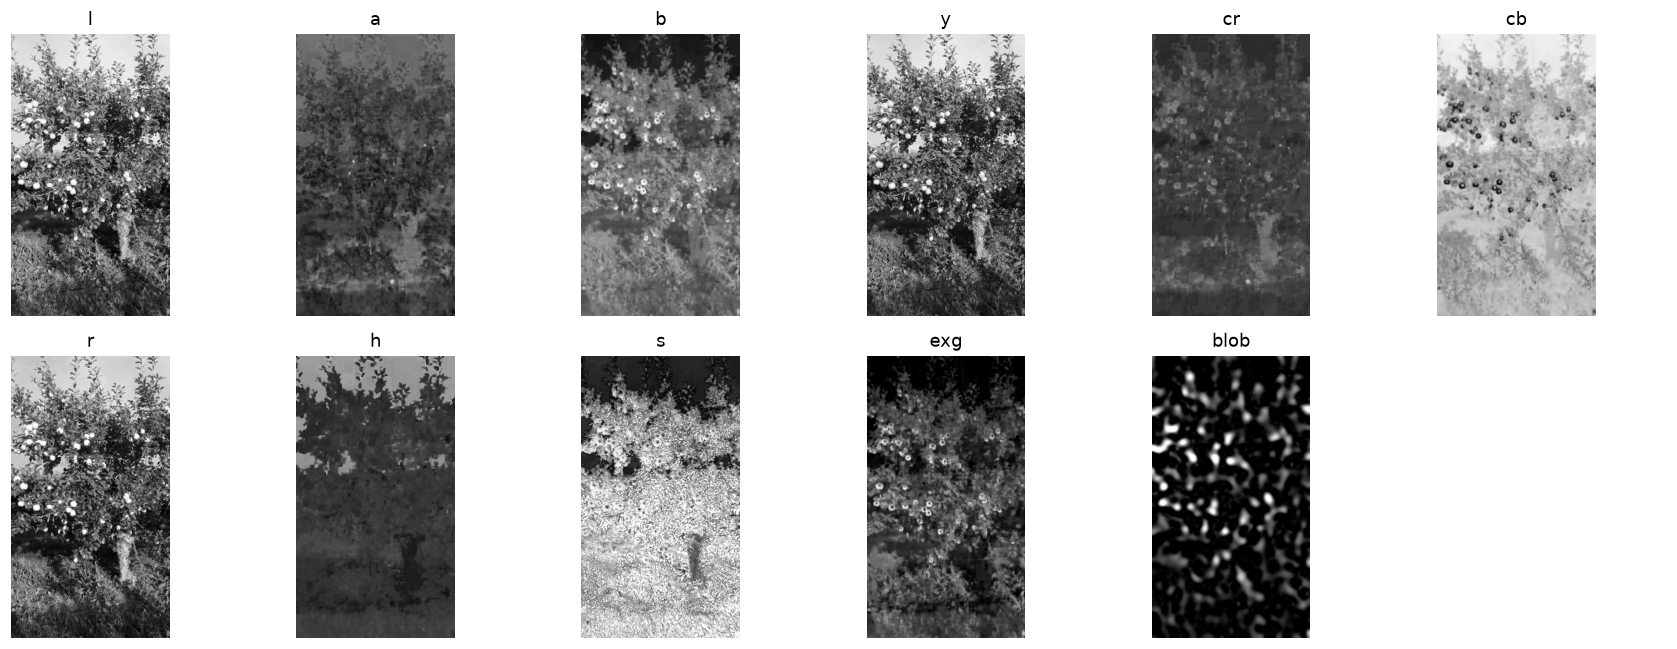

In [11]:
demo = preprocesar(imagenes[idx_train[0]], CFG, SIGMAS, DOG_REF)
print('forma', demo.shape)
for k, canal in enumerate(CANALES):
    x = demo[:, :, k]
    print(f'{k:2d} {canal:5s} min={x.min():3d} max={x.max():3d} media={x.mean():6.1f}')

fig, ax = plt.subplots(2, 6, figsize=FIG_TAM_CANALES)
for k, (a, canal) in enumerate(zip(ax.ravel(), CANALES)):
    a.imshow(demo[:, :, k], cmap='gray')
    a.set_title(canal)
for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()

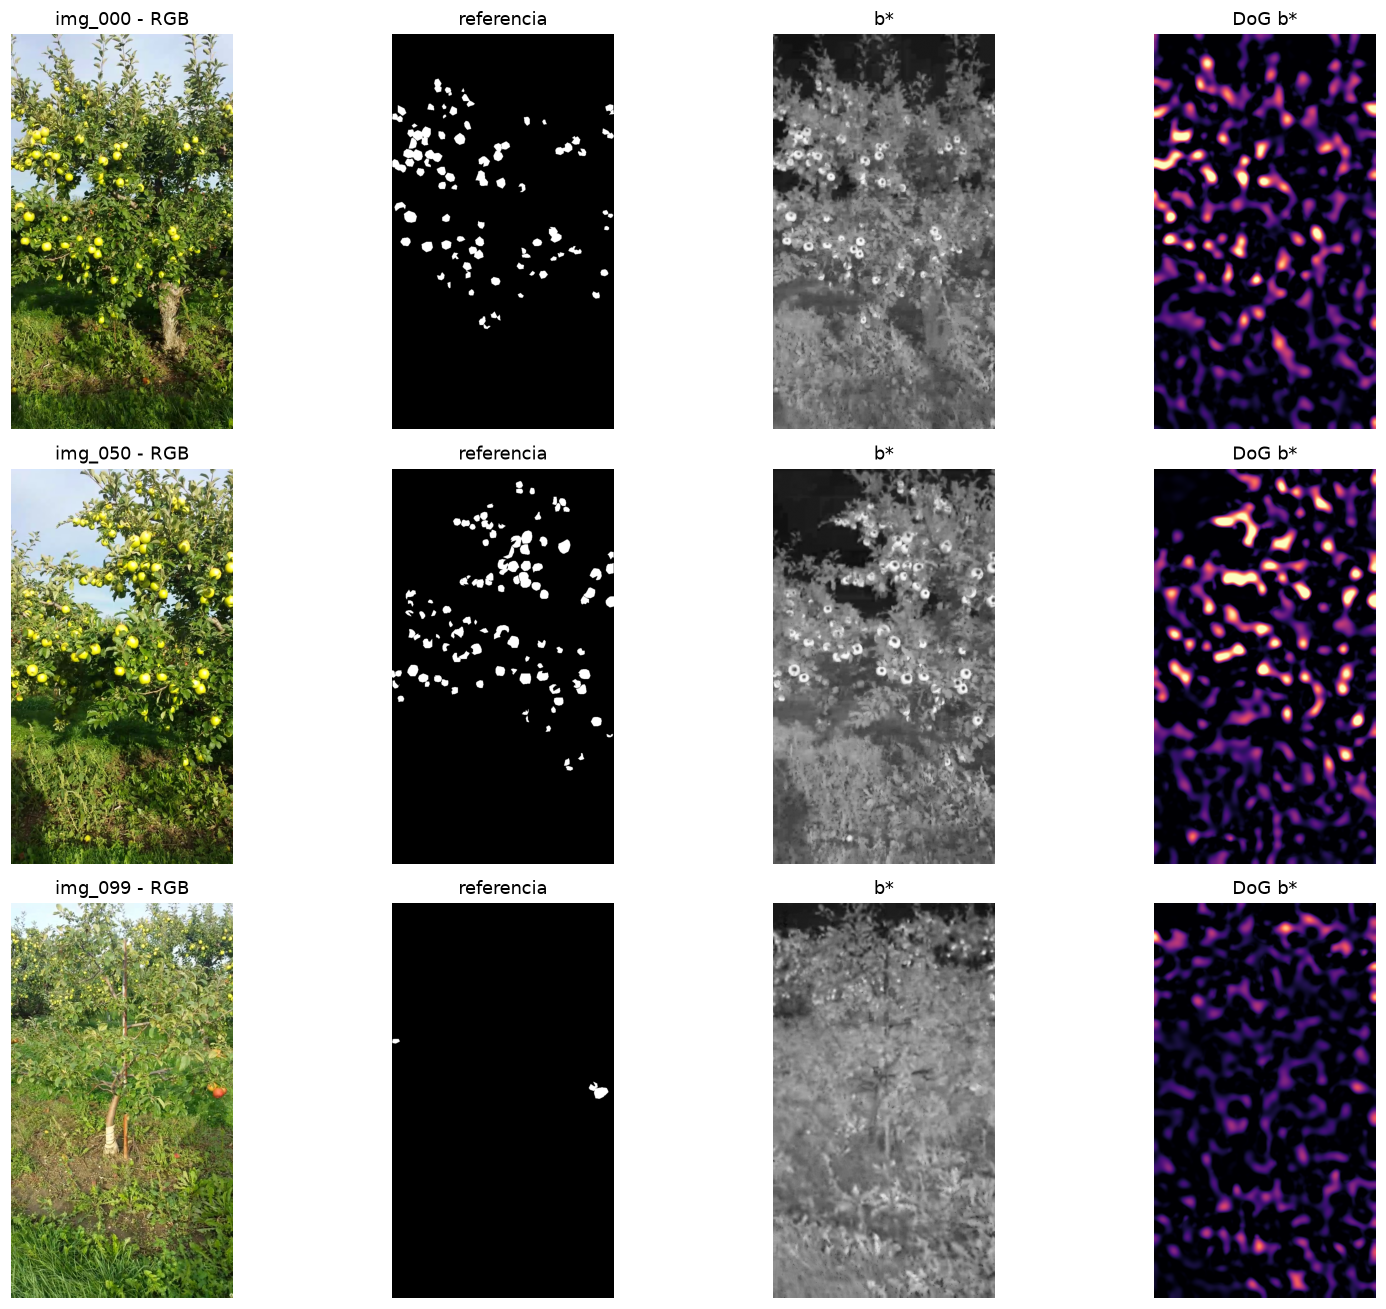

In [12]:
muestras = [idx_train[0], idx_train[len(idx_train) // 2], idx_train[-1]]
fig, ax = plt.subplots(
    len(muestras), 4,
    figsize=(FIG_TAM_MUESTRAS[0], FIG_TAM_MUESTRAS[1] * len(muestras)))
for fila, i in enumerate(muestras):
    img = imagenes[i]
    prep = preparar_rgb(img, CFG)
    b = cv.cvtColor(prep, cv.COLOR_RGB2Lab)[:, :, 2]
    blob = normalizar_dog(dog_multiescala(b, SIGMAS, CFG.dog_ratio), DOG_REF)
    ax[fila, 0].imshow(img)
    ax[fila, 0].set_title(f'{nombres[i]} - RGB')
    ax[fila, 1].imshow(mascaras[i], cmap='gray')
    ax[fila, 1].set_title('referencia')
    ax[fila, 2].imshow(b, cmap='gray')
    ax[fila, 2].set_title('b*')
    ax[fila, 3].imshow(blob, cmap='magma')
    ax[fila, 3].set_title('DoG b*')
    for a in ax[fila]:
        a.axis('off')
plt.tight_layout()
plt.show()


## 8. Grid search de preprocesado y guardado de cada configuración

Se recorre el grid de configuraciones. Para cada una se
calibra el DoG y se guardan los `.npy` en una subcarpeta propia, junto con
su `config.json`. 


In [ ]:
os.makedirs(RUTA_SALIDA_TEST, exist_ok=True)

for cfg in CONFIGS:
    radios, SIGMAS, DOG_REF = calibrar(imagenes, mascaras, idx_train, cfg)

    destino = os.path.join(RUTA_SALIDA_GRID, cfg.id())
    os.makedirs(destino, exist_ok=True)

    with open(os.path.join(destino, 'nombres.txt'), 'w') as f:
        f.write('\n'.join(nombres) + '\n')
    np.savez(os.path.join(destino, 'split.npz'),
             dev=idx_train, test=idx_test)

    for k, (nombre, img) in enumerate(zip(nombres, imagenes)):
        pila = preprocesar(img, cfg, SIGMAS, DOG_REF)
        np.save(os.path.join(destino, nombre + '.npy'), pila)

        if (k + 1) % CADA_N_IMAGENES == 0 or k == len(nombres) - 1:
            print(f'{k + 1}/{len(nombres)} imágenes de desarrollo guardadas')

    info = {
        'version': 'unificada',
        'canales': list(CANALES),
        'preprocesado': cfg.como_dict(),
        'forma': {
            'sigmas': list(SIGMAS),
            'dog_ratio': cfg.dog_ratio,
            'dog_ref': DOG_REF,
            'normalizacion': 'p99 de respuestas positivas en dev',
        },
        'split': {
            'dev': int(len(idx_train)),
            'test': int(len(idx_test)),
            'semilla': SEMILLA,
            'origen': 'propio',
        },
    }
    with open(os.path.join(destino, 'config.json'), 'w') as f:
        json.dump(info, f, indent=2)

    # Grid de test
    destino_test = os.path.join(RUTA_SALIDA_TEST, cfg.id())
    os.makedirs(destino_test, exist_ok=True)

    with open(os.path.join(destino_test, 'nombres.txt'), 'w') as f:
        f.write('\n'.join(nombres_test) + '\n')
    np.savez(os.path.join(destino_test, 'split.npz'),
             dev=np.array([], dtype=int), test=idx_test_externo)

    for k, (nombre, img) in enumerate(zip(nombres_test, imagenes_test)):
        pila = preprocesar(img, cfg, SIGMAS, DOG_REF)
        np.save(os.path.join(destino_test, nombre + '.npy'), pila)

        if (k + 1) % CADA_N_IMAGENES == 0 or k == len(nombres_test) - 1:
            print(f'{k + 1}/{len(nombres_test)} imágenes de test guardadas')

    info_test = {
        **info,
        'split': {
            'dev': 0,
            'test': int(len(nombres_test)),
            'semilla': SEMILLA,
            'origen': 'externo',
        },
    }
    with open(os.path.join(destino_test, 'config.json'), 'w') as f:
        json.dump(info_test, f, indent=2)

    print('Guardado', cfg.id())

10/100 imágenes de desarrollo guardadas
20/100 imágenes de desarrollo guardadas
30/100 imágenes de desarrollo guardadas
40/100 imágenes de desarrollo guardadas
50/100 imágenes de desarrollo guardadas
60/100 imágenes de desarrollo guardadas
70/100 imágenes de desarrollo guardadas
80/100 imágenes de desarrollo guardadas
90/100 imágenes de desarrollo guardadas
100/100 imágenes de desarrollo guardadas
10/30 imágenes de test guardadas
20/30 imágenes de test guardadas
30/30 imágenes de test guardadas
Guardado e1_ninguno_g0.7
10/100 imágenes de desarrollo guardadas
20/100 imágenes de desarrollo guardadas
30/100 imágenes de desarrollo guardadas
40/100 imágenes de desarrollo guardadas
50/100 imágenes de desarrollo guardadas
60/100 imágenes de desarrollo guardadas
70/100 imágenes de desarrollo guardadas
80/100 imágenes de desarrollo guardadas
90/100 imágenes de desarrollo guardadas
100/100 imágenes de desarrollo guardadas
10/30 imágenes de test guardadas
20/30 imágenes de test guardadas
30/30 im